# CS920 · Lab 3 (Week 4) — Learning representations with a neural network

**50 minutes · PyTorch, NumPy, Matplotlib and scikit-learn · CPU only (no GPU required)**

In **Lab 1**, we *chose* features $\phi$ and learnt the weights $v$. In **Lab 2**, we learnt the weight matrix $W$ of a linear digit classifier by minimising cross-entropy.

Today, **we will learn the features themselves**. We will see how a nonlinear representation can make a classification problem easier, and investigate what can go wrong during learning.

By the end, you should be able to:

1. Explain why a two-layer neural network can separate data that a linear classifier cannot.
2. Recognise learning rates that are too small or too large.
3. Explain why neural-network initialisation matters.
4. Interpret **training** and **validation** loss curves without confusing the two datasets.

**Working style:** Make a prediction before each experiment; run the code; explain what you observe. You will fill in **three short pieces of code**. Everything else is supplied so we can spend our time on the experiments.

### Start JupyterLab (DCS desktop)

If you already have your CS920 environment:

```bash
module load cs920-python
cd ~/cs920
source venv/bin/activate
mkdir -p lab3
cp /modules/cs920/labs/lab3/lab3.ipynb ~/cs920/lab3/
cd ~/cs920/lab3
jupyter lab
```

Open `lab3.ipynb` in JupyterLab. If you have not yet made `~/cs920/venv`, first create it **after** loading the module, following the Lab 1 setup instructions.

Run notebook cells in order (**Shift+Enter**). This lab generates its own data: **no downloads**.

## 1. Why learn a representation? (about 12 minutes)

Our inputs are points $x\in\mathbb R^2$ belonging to two classes $y\in\{0,1\}$. A linear classifier assigns scores

$$S_W(x,j)=(Wx+b)_j,$$

then predicts the class with the larger score. Its decision boundary is a straight line. Can a straight line separate *two interleaving moons*?

We use a **training set** to learn parameters and a separate **validation set** to evaluate them. Both are drawn from the same data-generating process; the validation labels will never be used for gradient updates.

Training set:   (100, 2)
Validation set: (550, 2)


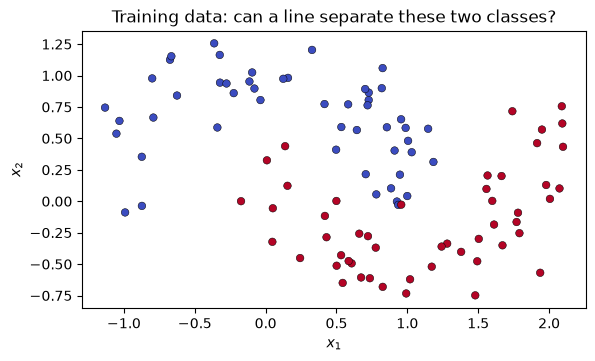

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

# Keep this light for shared DCS lab desktops.
torch.set_num_threads(min(2, torch.get_num_threads()))

# Fixed data and split: everyone sees the same experiment.
X_np, y_np = make_moons(n_samples=650, noise=0.20, random_state=17)
Xtr_np, Xva_np, ytr_np, yva_np = train_test_split(
    X_np, y_np, train_size=100, stratify=y_np, random_state=23
)
X_train = torch.tensor(Xtr_np, dtype=torch.float32)
y_train = torch.tensor(ytr_np, dtype=torch.long)
X_val   = torch.tensor(Xva_np, dtype=torch.float32)
y_val   = torch.tensor(yva_np, dtype=torch.long)

print(f"Training set:   {tuple(X_train.shape)}")
print(f"Validation set: {tuple(X_val.shape)}")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.scatter(Xtr_np[:, 0], Xtr_np[:, 1], c=ytr_np, cmap="coolwarm", edgecolors="k", linewidths=.35, s=30)
ax.set(xlabel=r"$x_1$", ylabel=r"$x_2$", title="Training data: can a line separate these two classes?")
plt.show()

### From fixed features to learnt features

A two-layer neural network uses scores

$$\boxed{S_{V,\theta}(x,j)=\big(V\phi_\theta(x)+c\big)_j,\quad
\phi_\theta(x)=\mathrm{ReLU}(Ax+b).}$$

Here $A\in\mathbb R^{h\times2}$ and $b\in\mathbb R^h$ define $h$ learnt features, and $V\in\mathbb R^{2\times h}$ and $c\in\mathbb R^2$ combine them into two class scores.

**What's new:** we now learn **both** $\theta=(A,b)$ and $(V,c)$. The loss is the same multiclass cross-entropy used in Lab 2. PyTorch will calculate its gradients for us; we do not need to derive backpropagation in this practical.

**Task A (one line):** Complete the nonlinear activation in `make_mlp` below.

In [ ]:
def make_mlp(width=16, seed=3, use_relu=True, zero_init=False):
    """Create a 2 -> width -> 2 network. Reinitialise for fair comparisons."""
    torch.manual_seed(seed)
    layers = [nn.Linear(2, width)]
    if use_relu:
        layers.append(...)       # TODO A: insert the ReLU activation nn.ReLU()
    layers.append(nn.Linear(width, 2))
    model = nn.Sequential(*layers)
    if zero_init:
        with torch.no_grad():
            for parameter in model.parameters():
                parameter.zero_()
    return model

# Check your architecture before continuing.
_check = make_mlp()
assert isinstance(_check[1], nn.ReLU), "Task A: put nn.ReLU() in the hidden layer."
assert _check(torch.zeros(5, 2)).shape == (5, 2)
print("Task A passed: a nonlinear two-layer score model.")

### Learning with cross-entropy

For the training data, we minimise

$$L_{\mathrm{train}}(\Theta)=\frac1n\sum_{r=1}^n
\left[-S_\Theta(x_r,y_r)+\log\sum_{j=0}^{1} e^{S_\Theta(x_r,j)}\right],$$

where $\Theta$ denotes *all* trainable parameters. The update is ordinary **full-batch gradient descent**:

$$\Theta \leftarrow \Theta-\eta\nabla_\Theta L_{\mathrm{train}}(\Theta).$$

Each update uses **all training examples**. We are **not** introducing stochastic or mini-batch gradient descent today.

**Task B (one line):** Complete the parameter update below. `loss.backward()` calculates the gradients; the update should not itself be differentiated.

In [ ]:
def accuracy(model, X, y):
    with torch.no_grad():
        return (model(X).argmax(dim=1) == y).float().mean().item()


def train_model(model, Xtr, ytr, Xva, yva, *, learning_rate=0.3,
                steps=700, record_every=25):
    """Full-batch gradient descent, recording train and validation losses."""
    history = {"step": [], "train": [], "val": []}

    for step in range(steps + 1):
        # Record loss values; validation is evaluated but NEVER used for updates.
        if step % record_every == 0 or step == steps:
            with torch.no_grad():
                history["step"].append(step)
                history["train"].append(F.cross_entropy(model(Xtr), ytr).item())
                history["val"].append(F.cross_entropy(model(Xva), yva).item())

        if step == steps:
            break

        model.zero_grad(set_to_none=True)
        loss = F.cross_entropy(model(Xtr), ytr)
        loss.backward()  # PyTorch computes gradients of the complete network.

        with torch.no_grad():
            for parameter in model.parameters():
                parameter -= ...  # TODO B: learning_rate = learning rate; parameter.grad = current gradient

    return history

# Tiny test: the update must actually change the model parameters.
_test = make_mlp(seed=99)
_before = [p.detach().clone() for p in _test.parameters()]
_ = train_model(_test, X_train, y_train, X_val, y_val, steps=2)
assert any(not torch.equal(a, p) for a, p in zip(_before, _test.parameters())), \
    "Task B: the gradient-descent step did not update any parameters."
print("Task B passed: parameters change after a gradient-descent update.")

**Stop and predict:** Will both models learn a straight decision boundary? Which will perform better on the validation set? Run the next cell and compare.

In [ ]:
# A linear classifier: learnt affine scores, but no nonlinear hidden features.
torch.manual_seed(3)
linear_model = nn.Linear(2, 2)
linear_history = train_model(
    linear_model, X_train, y_train, X_val, y_val, learning_rate=.3, steps=700
)

# A network: the hidden feature map and final weights are both learnt.
mlp_model = make_mlp(width=16, seed=3)
mlp_history = train_model(
    mlp_model, X_train, y_train, X_val, y_val, learning_rate=.3, steps=700
)

print(f"Linear: validation accuracy {100 * accuracy(linear_model, X_val, y_val):.1f}%")
print(f"MLP:    validation accuracy {100 * accuracy(mlp_model, X_val, y_val):.1f}%")

In [ ]:
def plot_boundary(ax, model, X, y, title):
    """Colour the input plane by the predicted label."""
    x1 = np.linspace(-1.7, 2.7, 170)
    x2 = np.linspace(-1.25, 1.7, 130)
    xx, yy = np.meshgrid(x1, x2)
    grid = torch.tensor(np.column_stack([xx.ravel(), yy.ravel()]), dtype=torch.float32)
    with torch.no_grad():
        pred = model(grid).argmax(dim=1).numpy().reshape(xx.shape)
    ax.contourf(xx, yy, pred, levels=[-.5, .5, 1.5], cmap="coolwarm", alpha=.28)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=21,
               edgecolors="k", linewidths=.25)
    ax.set(xlabel=r"$x_1$", ylabel=r"$x_2$", title=title,
           xlim=(x1.min(), x1.max()), ylim=(x2.min(), x2.max()))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.7), sharex=True, sharey=True)
plot_boundary(axes[0], linear_model, Xtr_np, ytr_np, "Linear: straight boundary")
plot_boundary(axes[1], mlp_model, Xtr_np, ytr_np, "MLP: learnt nonlinear boundary")
plt.tight_layout()
plt.show()

## 2. Learning rate: too small / suitable / too large (about 10 minutes)

We keep **the same data and the same initial weights** and change only the step size $\eta$. A tiny $\eta$ makes slow progress; a large $\eta$ may overshoot and produce unstable loss.

**Predict first:** Which learning rate below will make the fastest reliable progress over **200 steps**?

In [ ]:
learning_rates = [0.001, 0.3, 20.0]
rate_histories = {}
for lr in learning_rates:
    model = make_mlp(width=16, seed=3)  # identical starting weights
    rate_histories[lr] = train_model(
        model, X_train, y_train, X_val, y_val,
        learning_rate=lr, steps=200, record_every=5
    )

fig, ax = plt.subplots(figsize=(7.0, 3.4))
for lr, h in rate_histories.items():
    ax.plot(h["step"], h["train"], label=f"learning rate = {lr:g}")
ax.set(xlabel="Full-batch updates", ylabel="Training cross-entropy",
       title="Same starting weights, different step sizes")
ax.set_yscale("log")  # log scale so both slow and unstable runs are visible
ax.legend()
plt.show()

for lr, h in rate_histories.items():
    print(f"eta={lr:>6g}: loss {h['train'][0]:.3f} -> {h['train'][-1]:.3f}")

**Explain:** Does a larger learning rate always learn faster? Why is an unstable curve not evidence that the model class is incapable of solving the problem?

## 3. Initialisation: does the starting point matter? (about 10 minutes)

A neural network has many trainable parameters. Even when we use the **same dataset, architecture, learning rate and number of steps**, different random initial weights can lead to different results.

To make this easier to see, temporarily use a *narrower network* with just two hidden neurons.

In [ ]:
initialisations = [("seed 0", 0, False),
                   ("seed 1", 1, False),
                   ("seed 3", 3, False),
                   ("all zeros", 3, True)]

fig, axes = plt.subplots(2, 2, figsize=(10, 6.5), sharex=True, sharey=True)
initialisation_results = []
for ax, (label, seed, zeros) in zip(axes.flat, initialisations):
    model = make_mlp(width=2, seed=seed, zero_init=zeros)
    h = train_model(model, X_train, y_train, X_val, y_val,
                    learning_rate=.3, steps=350)
    val_acc = accuracy(model, X_val, y_val)
    initialisation_results.append((label, h["train"][-1], val_acc))
    plot_boundary(ax, model, Xtr_np, ytr_np,
                  f"{label}: validation accuracy {100 * val_acc:.1f}%")
plt.tight_layout()
plt.show()

for label, train_loss, val_acc in initialisation_results:
    print(f"{label:>9}: train loss {train_loss:.3f}; val accuracy {100 * val_acc:.1f}%")

**Explain:** Why do different initialisations sometimes give different results?

## 4. Training loss versus validation loss (about 10 minutes)

An expressive neural network can eventually fit a small dataset extremely well without generalising equally well. To see this clearly, use just **20 of our original 100 training examples**, while keeping the **same 550 validation examples**. We do **not** alter the validation distribution or train on its labels.

Our training function *already* evaluates both losses. **Task C (one line):** complete the missing statement in the cell below to locate the iteration having the smallest validation loss.

In [ ]:
tiny_X, tiny_y = X_train[:20], y_train[:20]
long_model = make_mlp(width=16, seed=3)
long_history = train_model(
    long_model, tiny_X, tiny_y, X_val, y_val,
    learning_rate=.3, steps=2500, record_every=25
)

best_index = ...  # TODO C: index of the smallest value in long_history["val"]
best_step = long_history["step"][best_index]

fig, ax = plt.subplots(figsize=(7.0, 3.4))
ax.plot(long_history["step"], long_history["train"], label="Training loss (20 examples)")
ax.plot(long_history["step"], long_history["val"], label="Validation loss (550 examples)")
ax.axvline(best_step, linestyle="--", color="gray", label=f"Lowest val loss: step {best_step}")
ax.set(xlabel="Full-batch updates", ylabel="Average cross-entropy",
       title="Training loss can keep falling after validation loss stops improving")
ax.legend()
plt.show()

print(f"Smallest validation loss at step {best_step}")
print(f"Final training loss: {long_history['train'][-1]:.3f}")
print(f"Final validation loss: {long_history['val'][-1]:.3f}")

**Stop and explain:**

- Why is the training loss usually lower than the validation loss late in this run?
- Why must **only training examples** be used in the gradient update?
- When might you stop training if your goal is good performance on unseen data?

> Validation is for model selection/diagnosis. We should not interpret the validation minimum from one random split as a guaranteed optimal stopping time for all datasets.

## Exit ticket (last few minutes)

Discuss these with the student next to you:

1. In Lab 1 we chose $\phi$ and learnt $v$. Which parameters define the **learnt feature map** in today's network?
2. How is **changing the learning rate** different from **changing the initialisation**?
3. Can two models have similar training losses but different validation performance?
4. What mathematical property allows this neural network to bend its decision boundary?

**Takeaway:** a neural network learns *features* as well as the final classifier, but the training procedure and the amount of data strongly influence what is learnt.

---
## Optional extension (after class): remove the nonlinearity

**Prediction:** What changes if we remove `ReLU` but keep two affine layers? Will the result still have a curved decision boundary?

Recall that composing two affine maps is still affine:

$$V(Ax+b)+c=(VA)x+(Vb+c).$$

The following experiment uses `use_relu=False` in our same network constructor.

In [ ]:
affine_model = make_mlp(width=16, seed=3, use_relu=False)
_ = train_model(affine_model, X_train, y_train, X_val, y_val,
                learning_rate=.3, steps=700)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.7), sharex=True, sharey=True)
plot_boundary(axes[0], affine_model, Xtr_np, ytr_np, "Two affine layers, no ReLU")
plot_boundary(axes[1], mlp_model, Xtr_np, ytr_np, "Two layers with ReLU")
plt.tight_layout()
plt.show()

print(f"Without ReLU: {100 * accuracy(affine_model, X_val, y_val):.1f}% validation accuracy")
print(f"With ReLU:    {100 * accuracy(mlp_model, X_val, y_val):.1f}% validation accuracy")